**Activity 4 — Multi-format Data Loading & Visualization Challenge**

Place `students.csv`, `attendance.json`, and `extra.xlsx` in the same folder as the notebook before running these cells.

In [1]:
import numpy as np 
import pandas as pd
import matplotlib.pyplot as plt

students_file = pd.read_csv("students.csv")
attendance_file = pd.read_json("attendance.json")
extra_file = pd.read_excel("extra.xlsx")

print("Students:")
print(students_file.head())
print("\nAttendance:")
print(attendance_file.head())
print("\nBonus:")
print(extra_file.head())

Students:
        Name  Marks
0  Student_1     78
1  Student_2     91
2  Student_3     68
3  Student_4     54
4  Student_5     82

Attendance:
        Name  Attendance
0  Student_1          86
1  Student_2          56
2  Student_3          70
3  Student_4          58
4  Student_5          88

Bonus:
        Name  Bonus
0  Student_1      4
1  Student_2      7
2  Student_3      9
3  Student_4      8
4  Student_5      8


In [2]:
for frame in [students_file, attendance_file, extra_file]:
    frame.columns = [c.strip().title() for c in frame.columns]

combined = (
    students_file
    .merge(attendance_file, on="Name", how="inner")
    .merge(extra_file, on="Name", how="inner")
)

combined = combined[["Name", "Marks", "Attendance", "Bonus"]]
print(combined)

          Name  Marks  Attendance  Bonus
0    Student_1     78          86      4
1    Student_2     91          56      7
2    Student_3     68          70      9
3    Student_4     54          58      8
4    Student_5     82          88      8
5    Student_6     47          67      0
6    Student_7     60          53      8
7    Student_8     78          74      6
8    Student_9     97          63      8
9   Student_10     58          99      7
10  Student_11     62          58      0
11  Student_12     50          75      7
12  Student_13     50          51      7
13  Student_14     63          69      2
14  Student_15     92          77      0
15  Student_16     75          96      7
16  Student_17     79          56      2
17  Student_18     63          93      2
18  Student_19     42          57      0
19  Student_20     61          96      4
20  Student_21     92          84      9
21  Student_22     41          63      6
22  Student_23     63          66      9
23  Student_24  

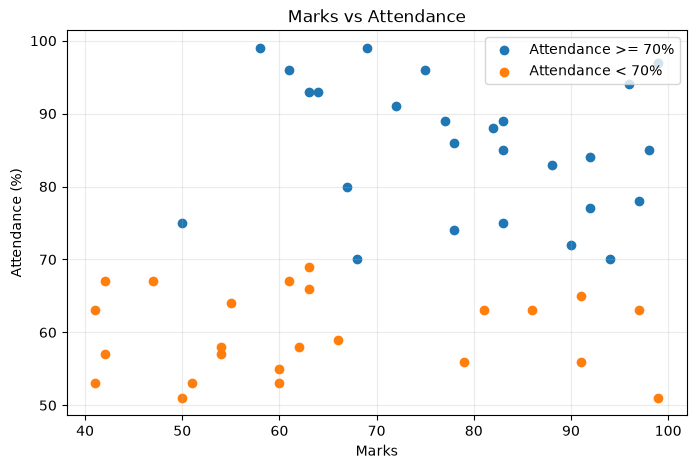

In [3]:
low_attendance = combined["Attendance"] < 70

plt.figure(figsize=(8, 5))
plt.scatter(
    combined.loc[~low_attendance, "Marks"],
    combined.loc[~low_attendance, "Attendance"],
    label="Attendance >= 70%"
)
plt.scatter(
    combined.loc[low_attendance, "Marks"],
    combined.loc[low_attendance, "Attendance"],
    label="Attendance < 70%"
)
plt.xlabel("Marks")
plt.ylabel("Attendance (%)")
plt.title("Marks vs Attendance")
plt.legend()
plt.grid(alpha=0.25)
plt.show()

In [4]:
name_one_hot = pd.get_dummies(
    combined["Name"], prefix="Student", dtype=int
)
combined_encoded = pd.concat(
    [combined.drop(columns="Name"), name_one_hot], axis=1
)

print(combined_encoded)

    Marks  Attendance  Bonus  Student_Student_1  Student_Student_10  \
0      78          86      4                  1                   0   
1      91          56      7                  0                   0   
2      68          70      9                  0                   0   
3      54          58      8                  0                   0   
4      82          88      8                  0                   0   
5      47          67      0                  0                   0   
6      60          53      8                  0                   0   
7      78          74      6                  0                   0   
8      97          63      8                  0                   0   
9      58          99      7                  0                   1   
10     62          58      0                  0                   0   
11     50          75      7                  0                   0   
12     50          51      7                  0                   0   
13    